# 05 · Visualizaciones, reporte e implicaciones

**Objetivo:** Mostrar a directores y dueños si la competencia cercana cambia el precio de una tienda, como caso de competencia local para decisiones de expansión y de precio por tienda.

**Pregunta:** ¿Cómo se comunica el hallazgo y qué hace cada audiencia?

Convenciones: **verde ▲** = la tienda con competidor cerca cobra más; **rojo ▼** = cobra menos; gris = no
distinta de cero (el intervalo cruza 0); dorado = referencia (sin competidor = 0).

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import entorno
entorno.setup()
import profeco, tablas, estadistica as E, charts as C
import competencia as K
PROC, META, CHARTS, SOCIAL = entorno.PROC, entorno.META, entorno.CHARTS, entorno.SOCIAL
CFG = entorno.config()
reg = entorno.registrar
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
REPS = 500
foc = pd.read_csv(PROC / "tiendas_focales.csv")
ev = foc[foc.grupo.isin(K.EVALUABLES)].copy()
import graficas as G, reporte, plantillas, re
res = entorno.cifras()
ef = pd.read_csv(PROC / "efecto_2km.csv", index_col=0)
ty = pd.read_csv(PROC / "efecto_por_tipo.csv", index_col=0)
rad = pd.read_csv(PROC / "efecto_por_radio.csv", index_col=0)
cov = pd.read_csv(PROC / "cobertura_por_radio.csv")

## Gráfica principal: diferencia con y sin competidor, por cadena

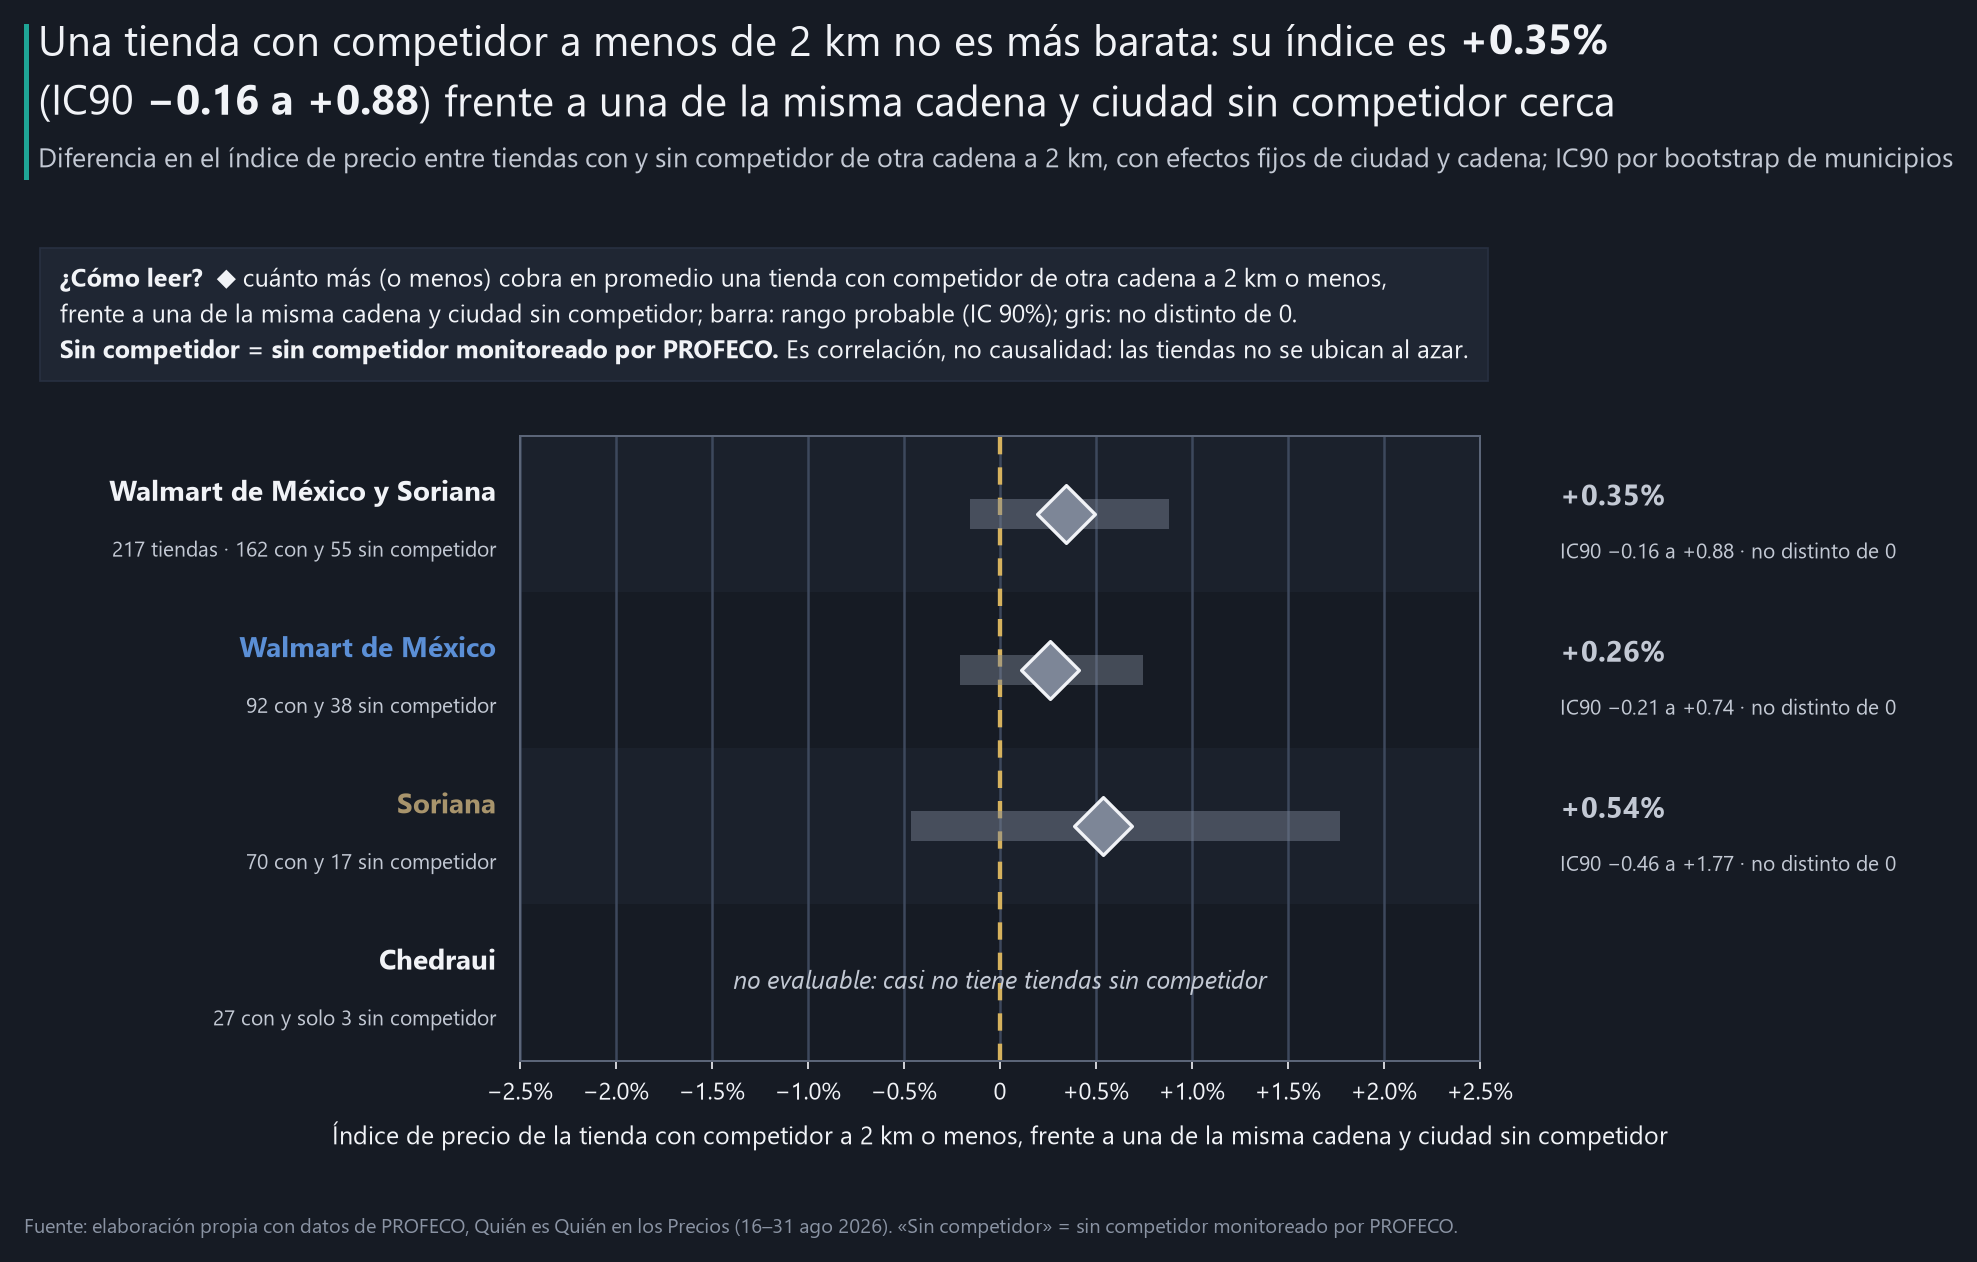

In [2]:
G.effect_by_group(ef, rad, res, CHARTS / "01_efecto_por_cadena.png", svg=True); plt.show()

### Versiones para publicar (1280×720 y 1080×1350)

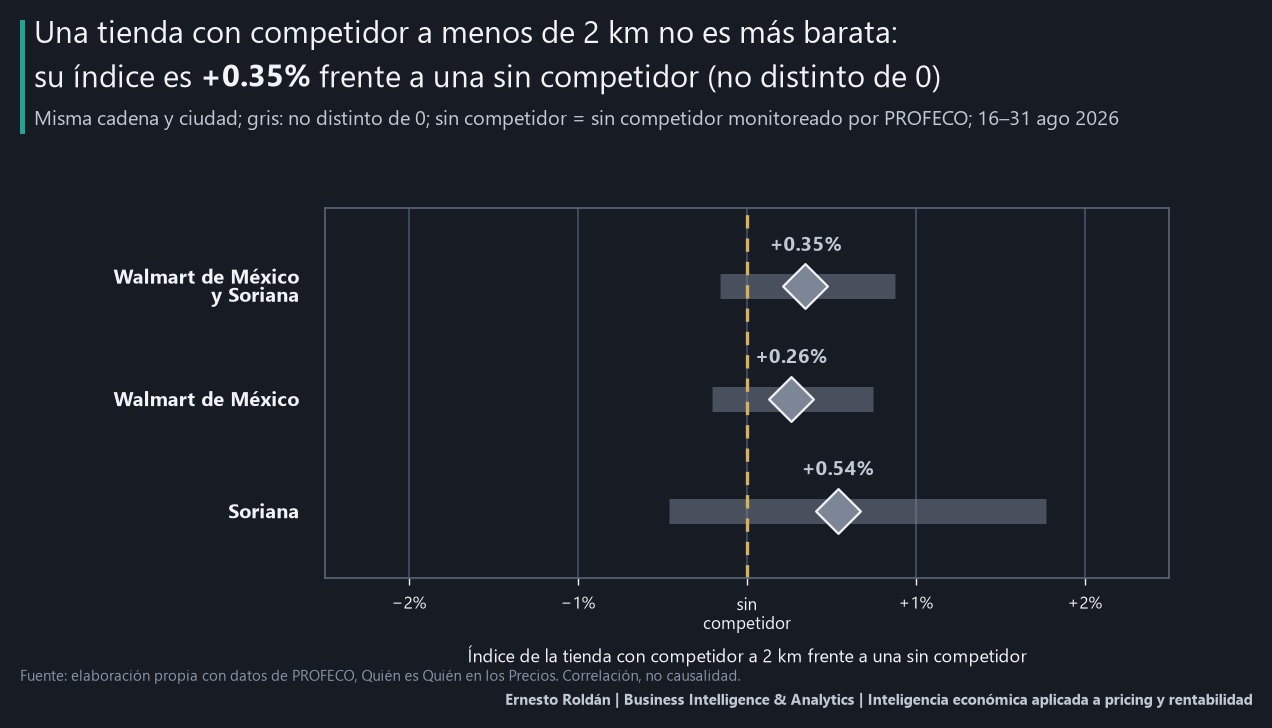

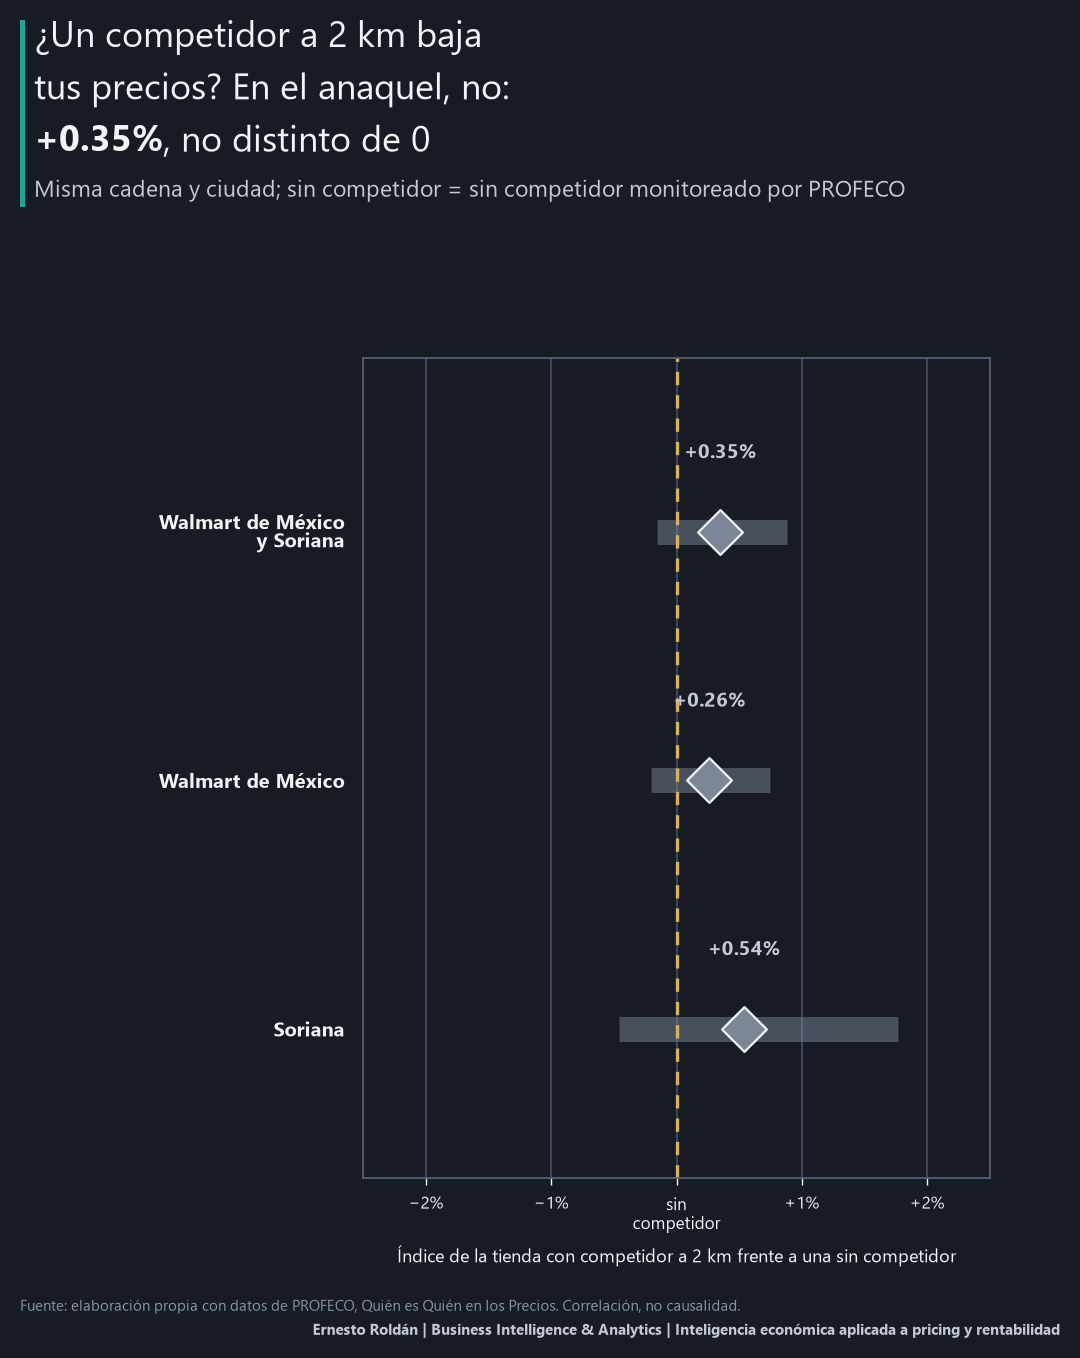

In [3]:
G.effect_social(ef, res, "horizontal", SOCIAL / "01_efecto_cadena_1280x720.png"); plt.show()
G.effect_social(ef, res, "vertical", SOCIAL / "01_efecto_cadena_1080x1350.png"); plt.show()

## Complementarias

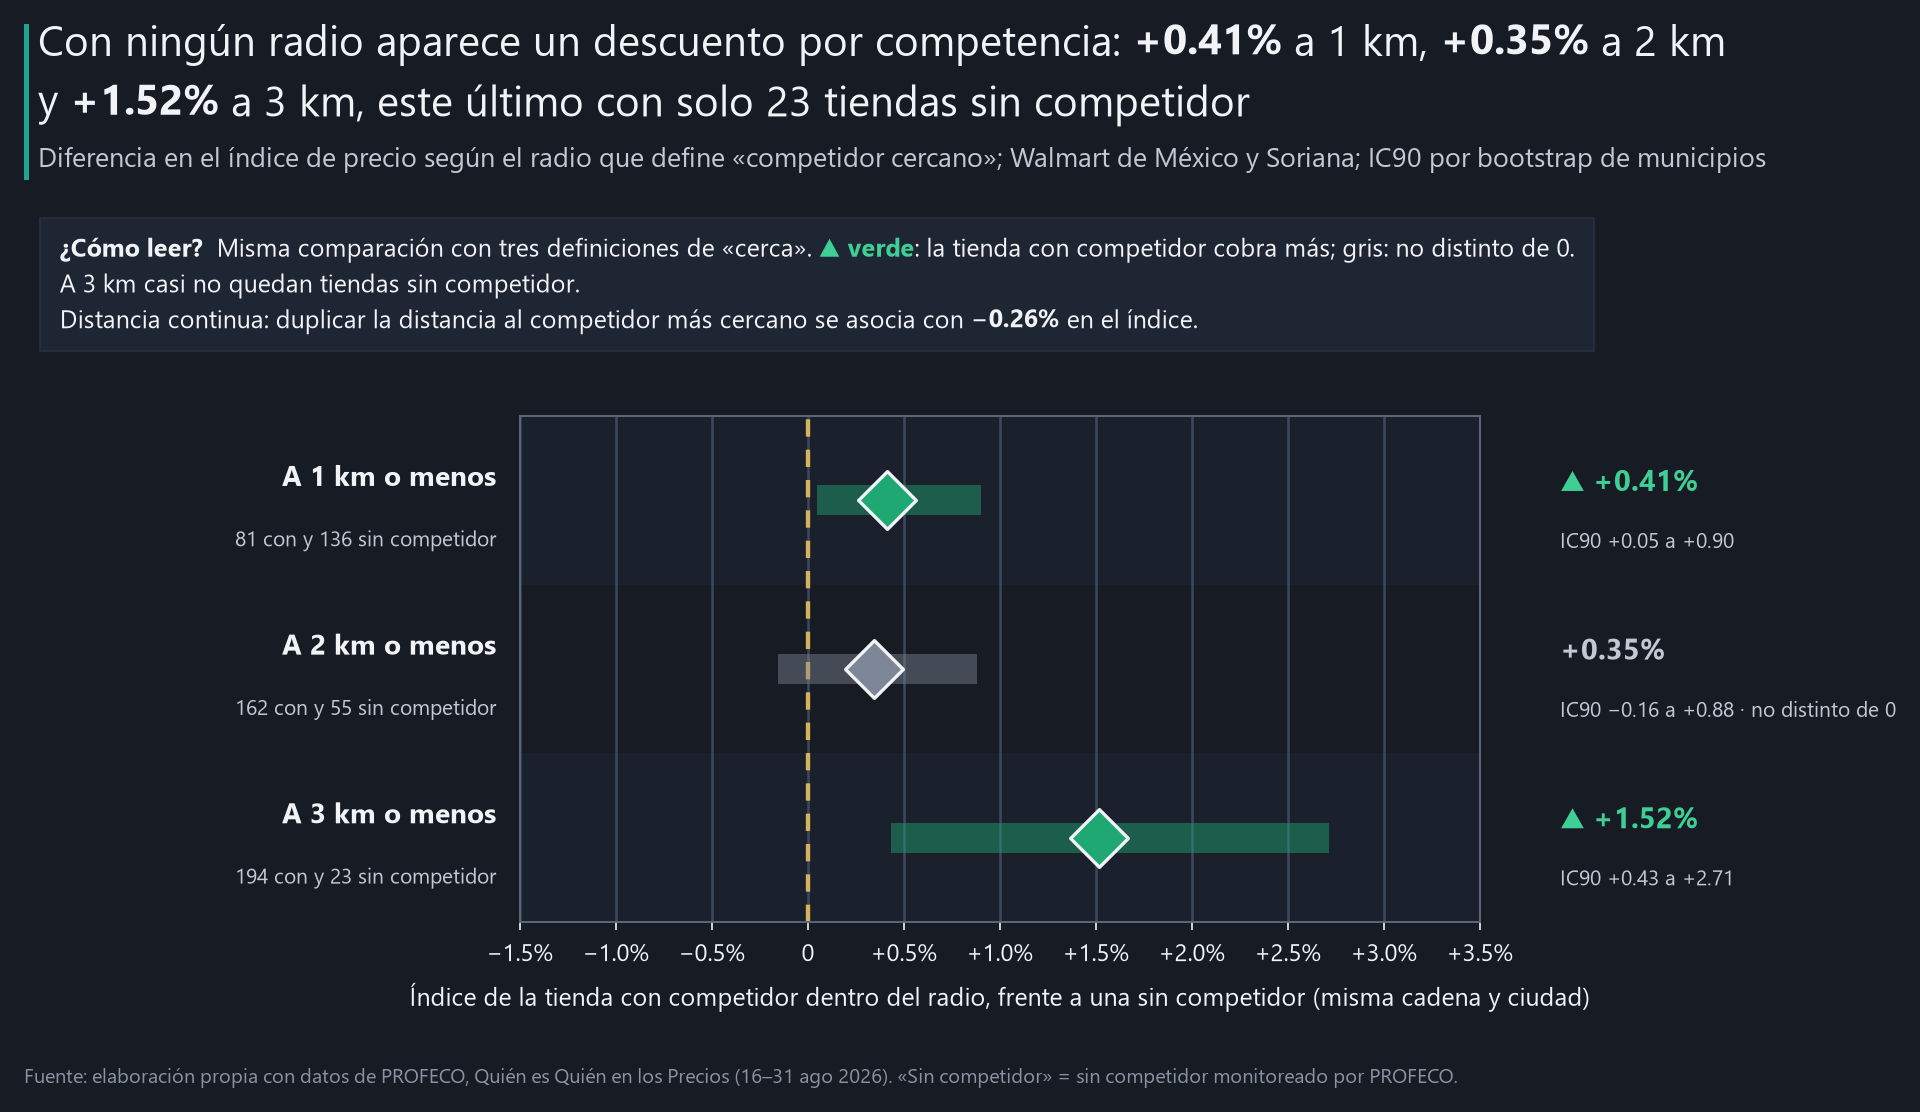

In [4]:
G.by_radius(rad, res, CHARTS / "02_efecto_por_radio.png"); plt.show()

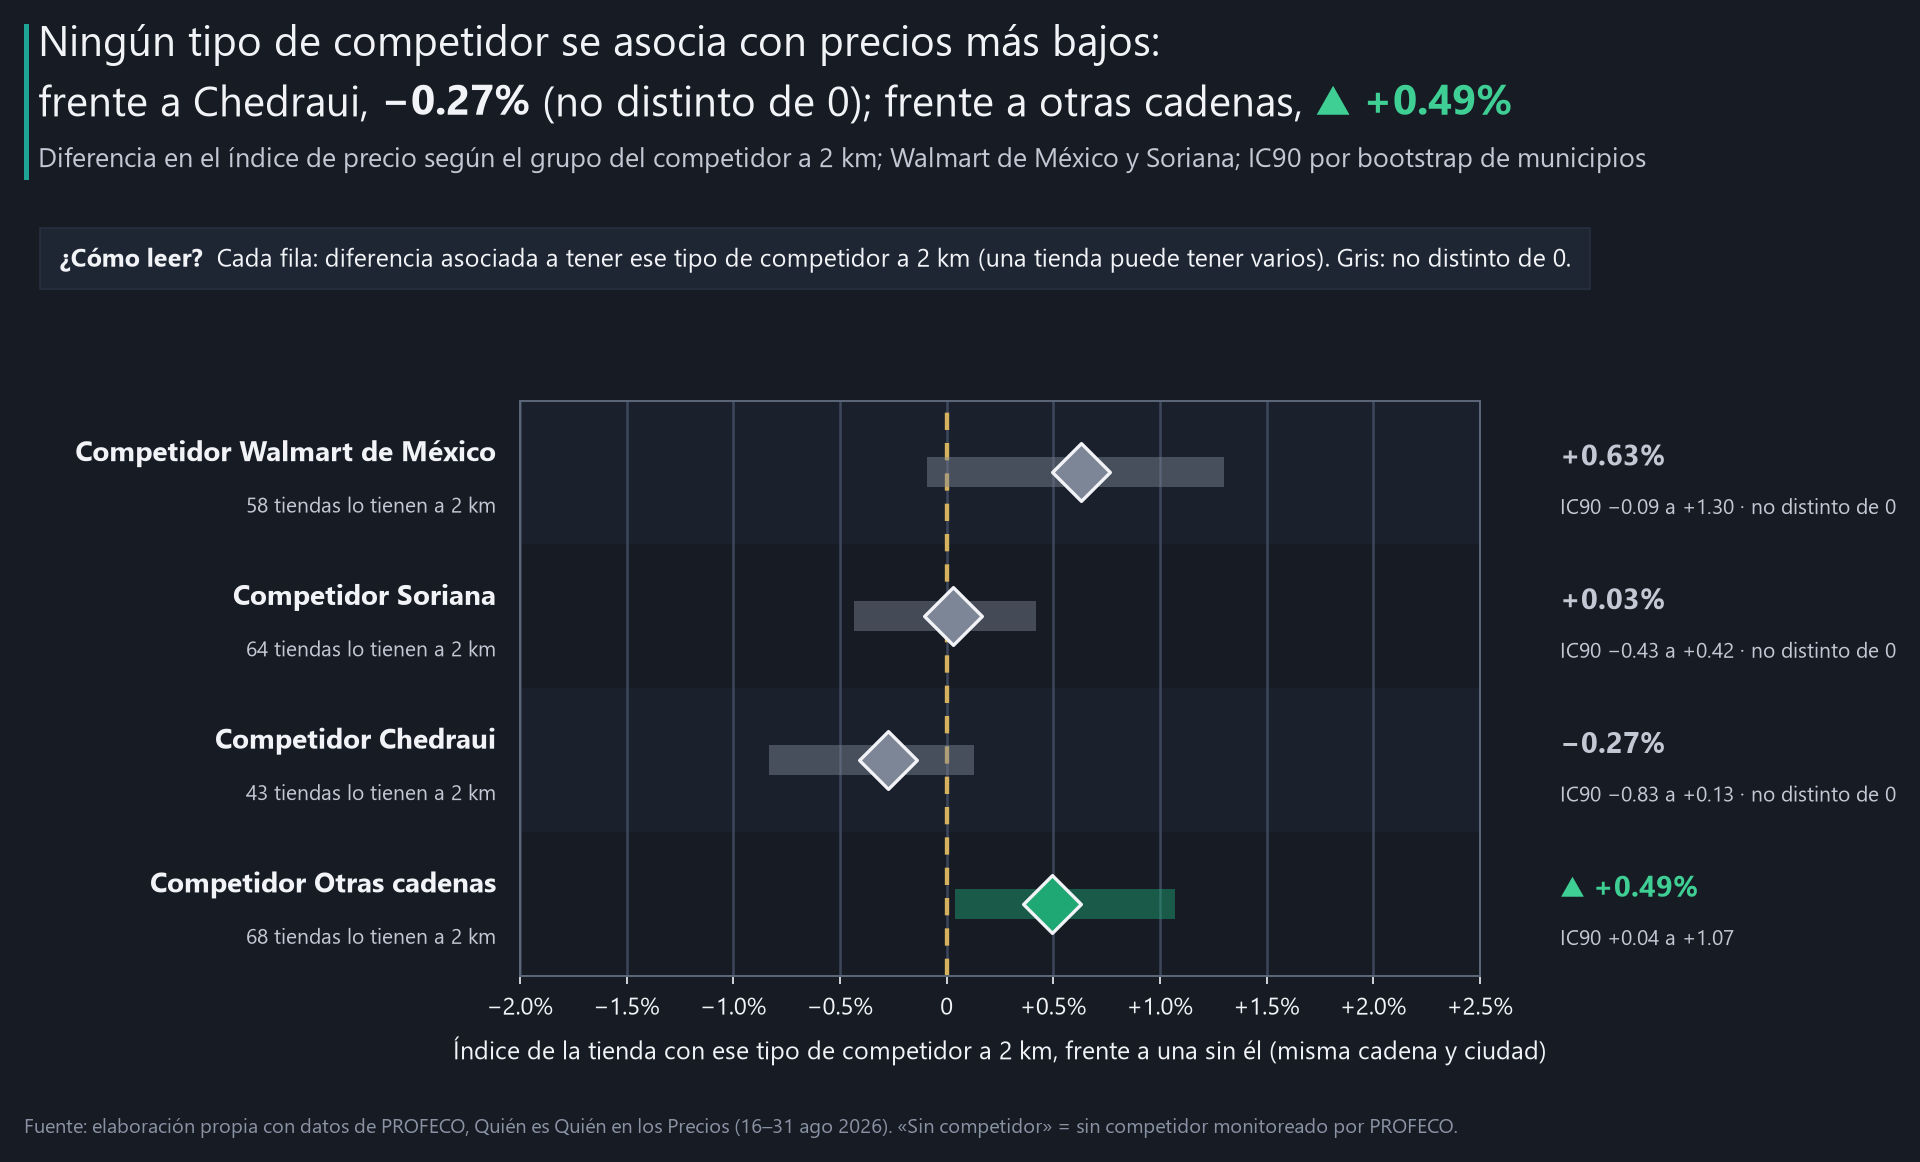

In [5]:
G.by_type(ty, ev, res, CHARTS / "03_efecto_por_tipo.png"); plt.show()

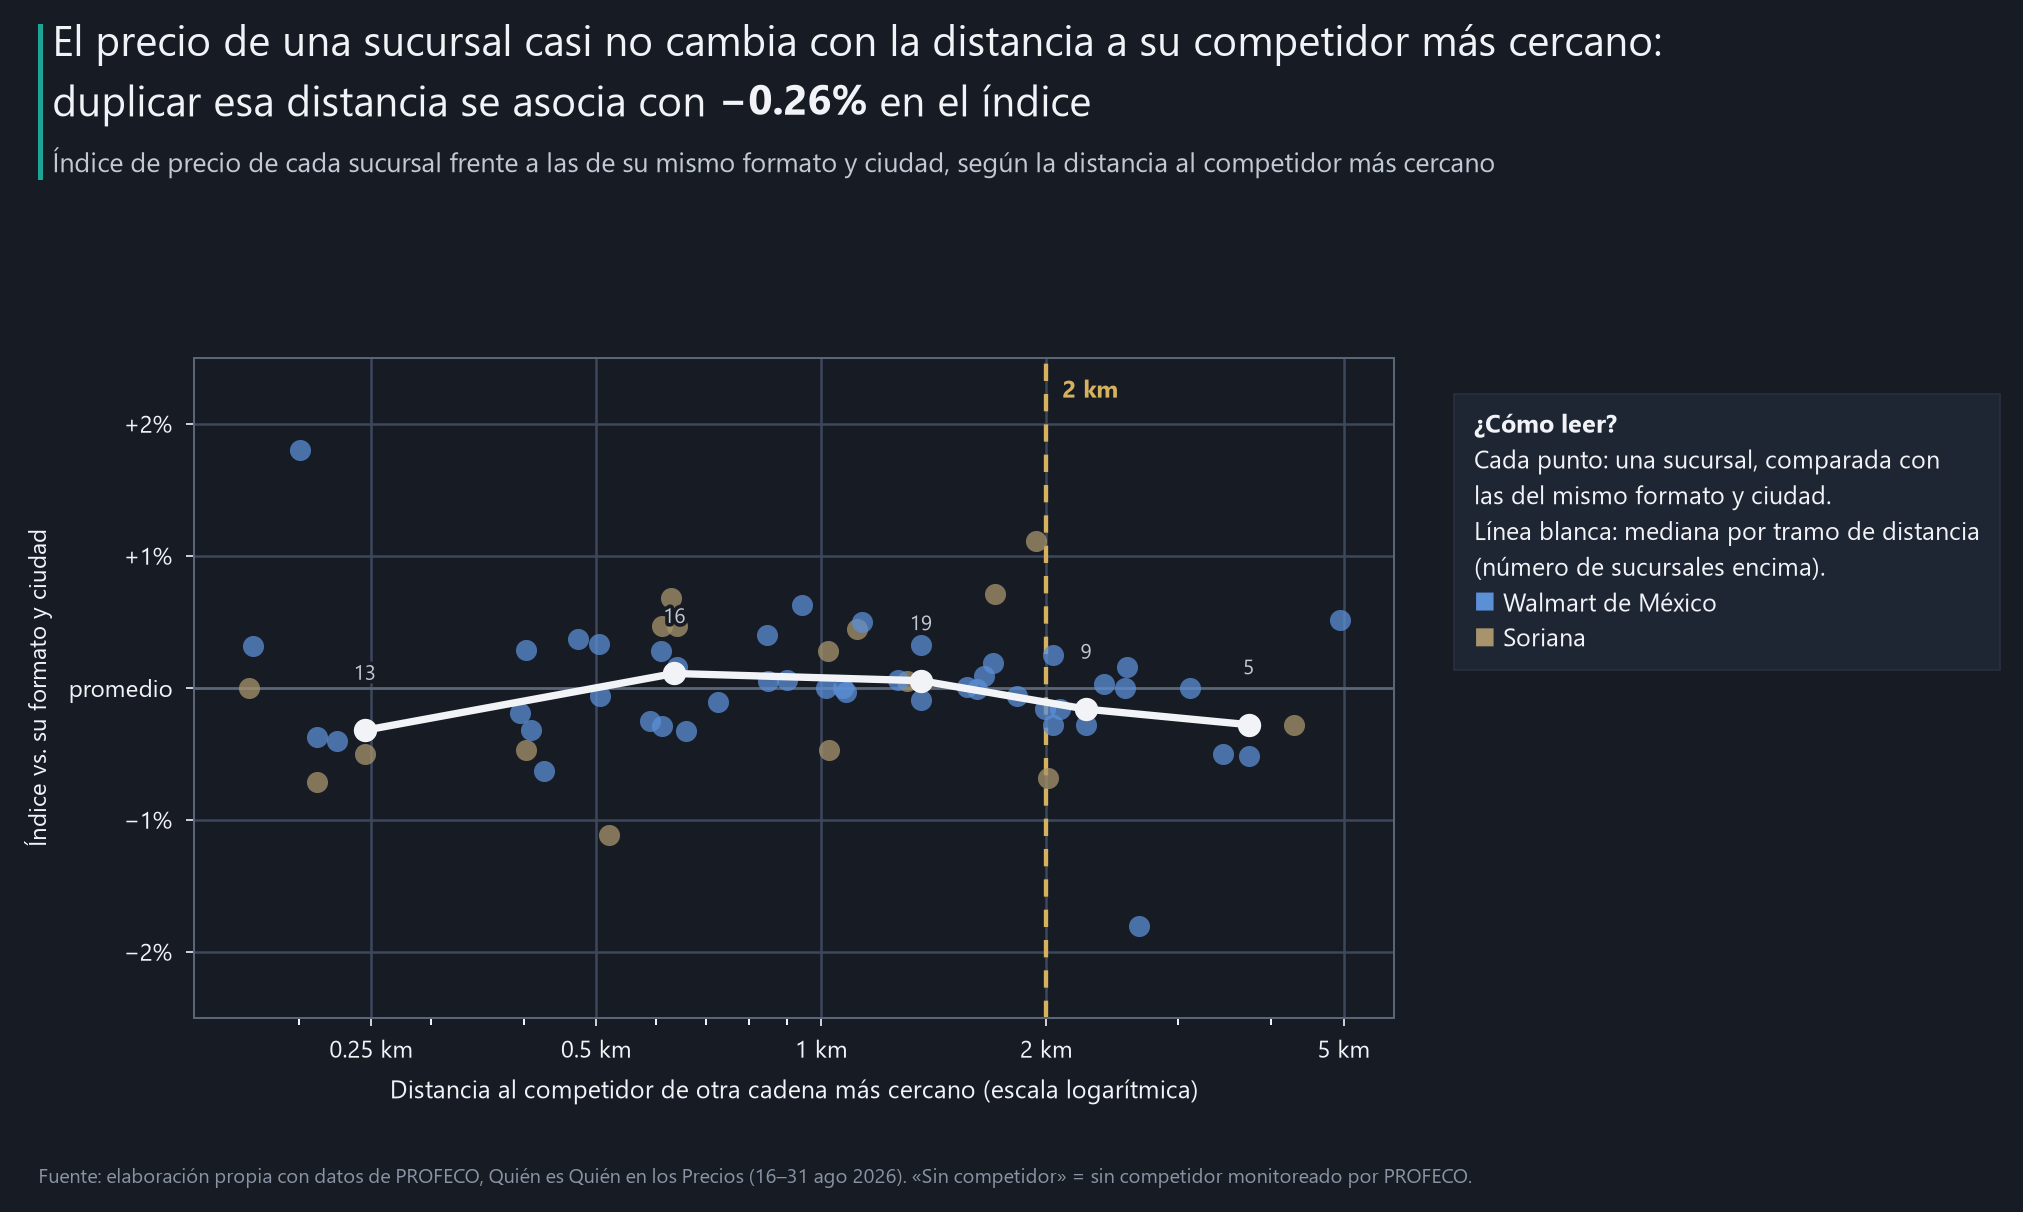

In [6]:
G.index_vs_distance(ev, res, CHARTS / "04_indice_vs_distancia.png"); plt.show()

## Reporte HTML y README

In [7]:
GALERIA = [(g_["titulo"], g_["pie"], CHARTS / g_["archivo"]) for g_ in CFG["graficas"]]
out = reporte.build(ef, rad, ty, cov, res, CFG, GALERIA, ROOT / "docs/index.html")
print(out, f"{out.stat().st_size / 1e6:.1f} MB")
estructura = (ROOT / "src/estructura.md").read_text(encoding="utf-8")
(ROOT / "README.md").write_text(plantillas.readme(CFG, res, estructura), encoding="utf-8")
txt = (ROOT / "README.md").read_text(encoding="utf-8")
assert not re.search(r"\{[a-z][a-z0-9_]*(:[^}]*)?\}", txt), re.findall(r"\{[a-z][a-z0-9_]*(?::[^}]*)?\}", txt)[:5]
print("README actualizado")

docs/index.html 5.7 MB
README actualizado


## Qué hacer con esto

In [8]:
for aud, acc in CFG["readme"]["acciones"].items():
    display(Markdown(f"**{aud}**\n\n" + "\n".join(f"- {plantillas.render(a, res)}" for a in acc)))

**Dirección comercial y de expansión**

- **No espere bajar precios al abrir junto a un competidor, ni subirlos donde no lo hay.** En el anaquel, la diferencia entre tiendas con y sin competidor a 2 km es de +0.35% y no se distingue de cero.
- **Evalúe la ubicación por tráfico y surtido, no por la guerra de precios local.** El precio de anaquel de las grandes cadenas se fija por ciudad: 86% de los productos cuesta lo mismo en todas las sucursales de Walmart de la ciudad.

**Dueño de tienda o cadena**

- **Si su precio varía entre sucursales, que sea por una razón.** En Soriana las sucursales del mismo formato difieren más que en Walmart, pero esa variación no responde a la competencia cercana: es costo sin estrategia.
- **La competencia local se libra en promociones, servicio y surtido.** Este análisis solo ve el precio de anaquel de la quincena; ahí la competencia de la esquina no se nota.

**Analista comercial**

- **Compare tiendas de la misma cadena y ciudad.** Comparar ciudades distintas confunde el costo de la ciudad con la competencia.
- **Revise la cobertura antes de estimar.** A 3 km solo quedan 23 tiendas sin competidor; con tan pocas, cualquier cifra es frágil.
- **Diga qué significa «sin competidor».** Aquí, sin competidor monitoreado por PROFECO.